In [3]:
from pathlib import Path
from collections import Counter
import re
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

# ============================================================
# Project paths
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "configs").exists()
    and (PROJECT_ROOT / "scripts").exists()
    and (PROJECT_ROOT / "data").exists()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Cannot find project root.")

    PROJECT_ROOT = PROJECT_ROOT.parent


FCD_DIR = PROJECT_ROOT / "data" / "processed" / "SUMO_ring_idm"

OUTPUT_DIR = PROJECT_ROOT / "analysis" / "outputs" / "cluster_distribution"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# # ============================================================
# # Simulation parameters
# # ============================================================

RING_LENGTH = 1200.0

# FREE_SPEED = 30.0
# JAM_RATIO = 0.5

# # Congestion criterion:
# # v / v_free < 0.5
# JAM_SPEED = FREE_SPEED * JAM_RATIO

# # Initial warm-up setting
# WARMUP = 100.0

# # Network edge offsets
# # Must be verified against ring_1200.net.xml
# EDGE_OFFSETS = {
#     "e0": 0.0,
#     "e1": 300.0,
#     "e2": 600.0,
#     "e3": 900.0,
# }

# print("Project root:", PROJECT_ROOT)
# print("FCD directory:", FCD_DIR)
# print("Output directory:", OUTPUT_DIR)
# print("Congestion threshold:", JAM_SPEED, "m/s")
# print("Warm-up:", WARMUP, "s")

# ============================================================
# Experiment settings
# ============================================================

SEED = 501

DENSITY_RUNS = {
    25: 30,
    30: 36,
    35: 42,
    40: 48,
    55: 66,
}

# Use the same time interval as the space-time diagrams
TIME_START = 600.0
TIME_END = 1800.0

FCD_FILES = {}

for density, n in DENSITY_RUNS.items():
    filename = f"fcd_idm_L1200_n{n}_s{SEED}.xml"

    fcd_file = FCD_DIR / filename

    if not fcd_file.exists():
        raise FileNotFoundError(f"FCD file not found: {fcd_file}")

    FCD_FILES[density] = fcd_file

    print(f"Density={density}, N={n}, Seed={SEED}: {filename}")

# ============================================================
# Load FCD data
# ============================================================


def load_fcd_data(
    fcd_file, ring_length=RING_LENGTH, time_start=TIME_START, time_end=TIME_END
):
    """
    Read SUMO FCD XML.

    Convert local edge positions into global ring positions.

    Returns:
        DataFrame with:
        time, vehicle_id, position, speed
    """

    edge_length = ring_length / 4

    edge_offsets = {
        "e0": 0.0,
        "e1": edge_length,
        "e2": 2 * edge_length,
        "e3": 3 * edge_length,
    }

    records = []

    for event, element in ET.iterparse(fcd_file, events=("end",)):
        if element.tag != "timestep":
            continue

        t = float(element.get("time"))

        if t < time_start:
            element.clear()
            continue

        if t >= time_end:
            break

        for vehicle in element.findall("vehicle"):
            vehicle_id = vehicle.get("id")

            lane_id = vehicle.get("lane")

            local_pos = float(vehicle.get("pos"))

            speed = float(vehicle.get("speed"))

            edge_id = lane_id.rsplit("_", 1)[0]

            if edge_id not in edge_offsets:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            global_pos = (edge_offsets[edge_id] + local_pos) % ring_length

            records.append(
                {
                    "time": t,
                    "vehicle_id": vehicle_id,
                    "position": global_pos,
                    "speed": speed,
                }
            )

        element.clear()

    if not records:
        raise ValueError(f"No observations found in {fcd_file}")

    df = pd.DataFrame(records)

    return df


# ============================================================
# Load all density experiments
# ============================================================

speed_data = {}

for density, fcd_file in FCD_FILES.items():
    print(f"\nLoading density = {density} veh/km")

    df = load_fcd_data(
        fcd_file=fcd_file,
        ring_length=RING_LENGTH,
        time_start=TIME_START,
        time_end=TIME_END,
    )

    speed_data[density] = df

    print(
        f"Observations: {len(df):,}\n"
        f"Vehicles: {df['vehicle_id'].nunique()}\n"
        f"Time steps: {df['time'].nunique()}"
    )

print("\nAll experiments loaded.")

Density=25, N=30, Seed=501: fcd_idm_L1200_n30_s501.xml
Density=30, N=36, Seed=501: fcd_idm_L1200_n36_s501.xml
Density=35, N=42, Seed=501: fcd_idm_L1200_n42_s501.xml
Density=40, N=48, Seed=501: fcd_idm_L1200_n48_s501.xml
Density=55, N=66, Seed=501: fcd_idm_L1200_n66_s501.xml

Loading density = 25 veh/km
Observations: 36,000
Vehicles: 30
Time steps: 1200

Loading density = 30 veh/km
Observations: 43,200
Vehicles: 36
Time steps: 1200

Loading density = 35 veh/km
Observations: 50,400
Vehicles: 42
Time steps: 1200

Loading density = 40 veh/km
Observations: 57,600
Vehicles: 48
Time steps: 1200

Loading density = 55 veh/km
Observations: 79,200
Vehicles: 66
Time steps: 1200

All experiments loaded.


In [ ]:
SPACE_BIN = 50.0  # metres
TIME_BIN = 10.0  # seconds


def calculate_local_traffic(df, density_label):
    data = df.copy()

    data["space_bin"] = np.floor(data["position"] / SPACE_BIN).astype(int)

    data["time_bin"] = np.floor((data["time"] - TIME_START) / TIME_BIN).astype(int)

    # First average over vehicles at each timestep and spatial bin.
    snapshot = (
        data.groupby(["time", "space_bin"])
        .agg(n_vehicles=("vehicle_id", "count"), mean_speed=("speed", "mean"))
        .reset_index()
    )

    # Include zero-vehicle bins to avoid inflating density.
    all_times = np.sort(data["time"].unique())
    n_space_bins = int(round(RING_LENGTH / SPACE_BIN))

    full_index = pd.MultiIndex.from_product(
        [all_times, range(n_space_bins)], names=["time", "space_bin"]
    )

    snapshot = (
        snapshot.set_index(["time", "space_bin"]).reindex(full_index).reset_index()
    )

    snapshot["n_vehicles"] = snapshot["n_vehicles"].fillna(0)
    snapshot["time_bin"] = np.floor((snapshot["time"] - TIME_START) / TIME_BIN).astype(
        int
    )

    # Average density over time, including empty snapshots.
    # Mean speed is weighted by the number of vehicle observations.
    snapshot["speed_sum"] = snapshot["mean_speed"].fillna(0) * snapshot["n_vehicles"]

    local = (
        snapshot.groupby(["time_bin", "space_bin"])
        .agg(
            mean_count=("n_vehicles", "mean"),
            speed_sum=("speed_sum", "sum"),
            vehicle_observations=("n_vehicles", "sum"),
        )
        .reset_index()
    )

    local["density"] = local["mean_count"] / (SPACE_BIN / 1000.0)

    local["speed"] = local["speed_sum"] / local["vehicle_observations"].replace(
        0, np.nan
    )

    local["global_density"] = density_label

    return local.dropna(subset=["speed"])


local_data = pd.concat(
    [calculate_local_traffic(df, density) for density, df in speed_data.items()],
    ignore_index=True,
)

print("Total local observations:", len(local_data))
display(local_data.head())


Total local observations: 14400


,time_bin,space_bin,mean_count,speed_sum,vehicle_observations,density,speed,global_density
0,0,0,1.3,256.23,13,26.0,19.71,25
1,0,1,1.3,256.23,13,26.0,19.71,25
2,0,2,1.2,236.52,12,24.0,19.71,25
3,0,3,1.2,236.52,12,24.0,19.71,25
4,0,4,1.3,256.23,13,26.0,19.71,25


In [ ]:
# ============================================================
# 2. Fundamental diagram models
# ============================================================


def greenshields(rho, vf, rho_j):
    return vf * (1 - rho / rho_j)


def greenberg(rho, vm, rho_j):
    return vm * np.log(rho_j / rho)


def underwood(rho, vf, rho_0):
    return vf * np.exp(-rho / rho_0)


# ============================================================
# 3. Fit models
# ============================================================

fit_data = local_data[(local_data["density"] > 0) & (local_data["speed"] >= 0)].copy()

rho = fit_data["density"].to_numpy()
v = fit_data["speed"].to_numpy()

models = {
    "Greenshields": (greenshields, [30, 120], ([0, rho.max() + 1e-6], [100, 1000])),
    "Greenberg": (greenberg, [10, 120], ([0, rho.max() + 1e-6], [100, 1000])),
    "Underwood": (underwood, [30, 40], ([0, 0.01], [100, 1000])),
}

fit_results = {}
rows = []

for name, (func, p0, bounds) in models.items():
    popt, pcov = curve_fit(func, rho, v, p0=p0, bounds=bounds, maxfev=20000)

    prediction = func(rho, *popt)

    ss_res = np.sum((v - prediction) ** 2)
    ss_tot = np.sum((v - v.mean()) ** 2)

    r2 = 1 - ss_res / ss_tot
    rmse = np.sqrt(np.mean((v - prediction) ** 2))

    fit_results[name] = {"function": func, "parameters": popt, "r2": r2, "rmse": rmse}

    rows.append(
        {
            "Model": name,
            "Parameter 1": popt[0],
            "Parameter 2": popt[1],
            "R-squared": r2,
            "RMSE (m/s)": rmse,
        }
    )

comparison_df = pd.DataFrame(rows)

display(comparison_df.round(4))


,Model,Parameter 1,Parameter 2,R-squared,RMSE (m/s)
0,Greenshields,25.0060,86.0000,0.8666,1.8736
1,Greenberg,13.5153,98.0087,0.9002,1.6203
2,Underwood,38.3783,34.3565,0.9050,1.5813


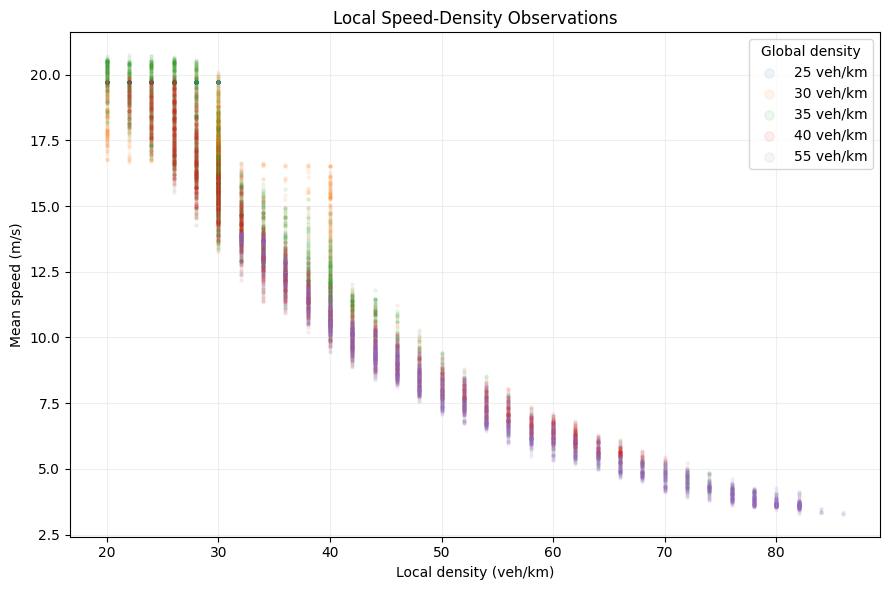

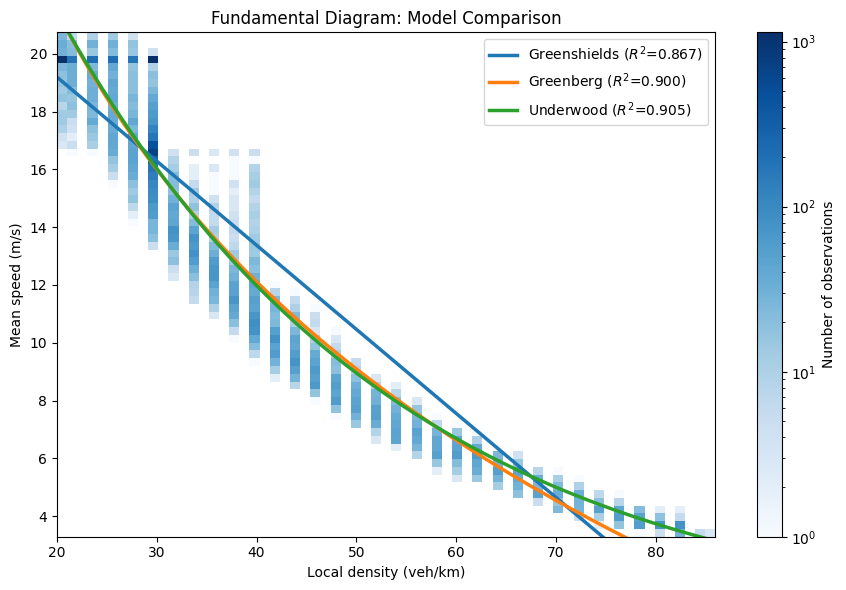

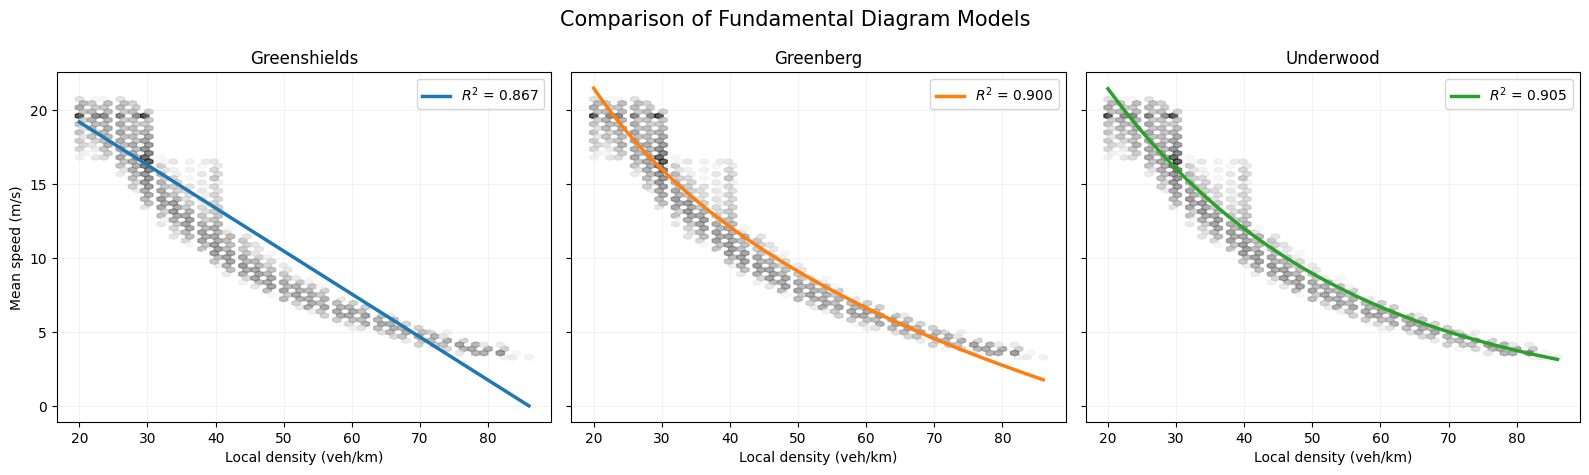

In [ ]:
# ============================================================
# Improved fundamental diagram visualization
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

densities = sorted(fit_data["global_density"].unique())

cmap = plt.get_cmap("tab10")

colors = {density: cmap(i % 10) for i, density in enumerate(densities)}

model_colors = {
    "Greenshields": "tab:blue",
    "Greenberg": "tab:orange",
    "Underwood": "tab:green",
}

rho_plot = np.linspace(max(0.01, rho.min()), rho.max(), 500)

# ============================================================
# Figure A: Observations by global density
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

for density, group in fit_data.groupby("global_density"):
    ax.scatter(
        group["density"],
        group["speed"],
        s=5,
        alpha=0.08,
        color=colors[density],
        rasterized=True,
        label=f"{density} veh/km",
    )

ax.set(
    xlabel="Local density (veh/km)",
    ylabel="Mean speed (m/s)",
    title="Local Speed-Density Observations",
)

ax.legend(title="Global density", markerscale=3)
ax.grid(alpha=0.2)

plt.tight_layout()
# plt.savefig(
#     OUTPUT_DIR / "fd_observations.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()


# ============================================================
# Figure B: Density heatmap with fitted models
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

h = ax.hist2d(rho, v, bins=[65, 65], cmap="Blues", norm=LogNorm(), cmin=1)

fig.colorbar(h[3], ax=ax, label="Number of observations")

for name, result in fit_results.items():
    func = result["function"]
    params = result["parameters"]

    ax.plot(
        rho_plot,
        func(rho_plot, *params),
        linewidth=2.5,
        color=model_colors[name],
        label=f"{name} ($R^2$={result['r2']:.3f})",
    )

ax.set(
    xlabel="Local density (veh/km)",
    ylabel="Mean speed (m/s)",
    title="Fundamental Diagram: Model Comparison",
)

ax.legend()
plt.tight_layout()

# plt.savefig(
#     OUTPUT_DIR / "fd_heatmap_comparison.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()


# ============================================================
# Figure C: Individual model fits
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)

for ax, (name, result) in zip(axes, fit_results.items()):
    ax.hexbin(rho, v, gridsize=55, cmap="Greys", mincnt=1, bins="log", alpha=0.65)

    ax.plot(
        rho_plot,
        result["function"](rho_plot, *result["parameters"]),
        color=model_colors[name],
        linewidth=2.5,
        label=f"$R^2$ = {result['r2']:.3f}",
    )

    ax.set_title(name)
    ax.set_xlabel("Local density (veh/km)")
    ax.legend()
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Mean speed (m/s)")

fig.suptitle("Comparison of Fundamental Diagram Models", fontsize=15)

plt.tight_layout()

# plt.savefig(
#     OUTPUT_DIR / "fd_individual_models.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()


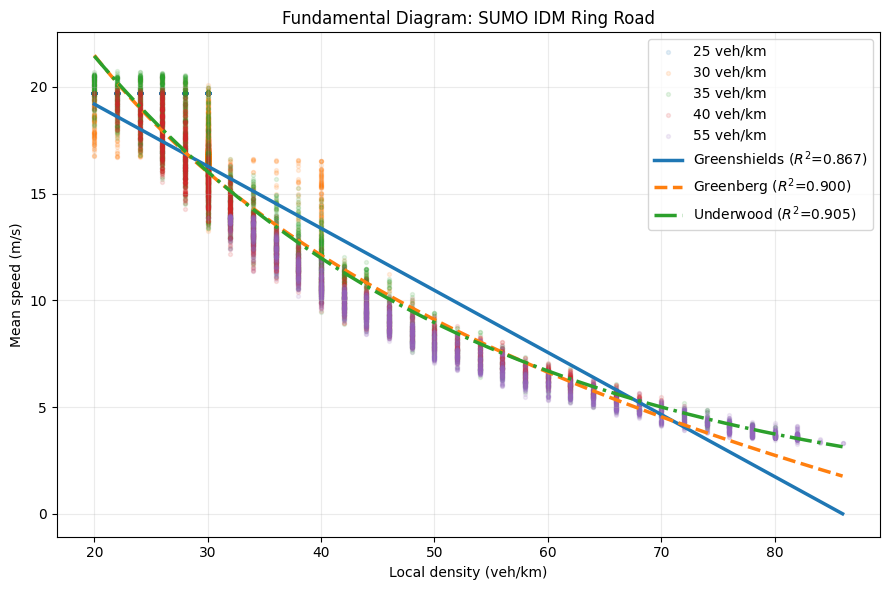

In [ ]:
# ============================================================
# 4. Plot model comparison
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

densities = sorted(fit_data["global_density"].unique())

cmap = plt.get_cmap("tab10")

colors = {density: cmap(i % 10) for i, density in enumerate(densities)}

for density, group in fit_data.groupby("global_density"):
    ax.scatter(
        group["density"],
        group["speed"],
        s=8,
        alpha=0.12,
        color=colors[density],
        label=f"{density} veh/km",
    )

rho_plot = np.linspace(max(0.01, rho.min()), rho.max(), 500)

line_styles = {"Greenshields": "-", "Greenberg": "--", "Underwood": "-."}

for name, result in fit_results.items():
    v_fit = result["function"](rho_plot, *result["parameters"])

    ax.plot(
        rho_plot,
        v_fit,
        linestyle=line_styles[name],
        linewidth=2.5,
        label=f"{name} ($R^2$={result['r2']:.3f})",
    )

ax.set_xlabel("Local density (veh/km)")
ax.set_ylabel("Mean speed (m/s)")
ax.set_title("Fundamental Diagram: SUMO IDM Ring Road")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fundamental_diagram_comparison.png", dpi=300, bbox_inches="tight"
)

plt.show()
